# Phase II — Reddit Activity and Trading Volume

## Project objective

Our project examines whether Reddit ticker mentions and sentiment can help
predict unusually high trading volume on the next trading day. We plan to
compare a model using historical trading volume alone with a model that
also includes Reddit activity and sentiment features.

## Data source and scope

Source: https://huggingface.co/datasets/SocialGrep/reddit-wallstreetbets-aug-2021

This notebook explores 1,001,160 comments from r/wallstreetbets collected
during August 2021. The dataset comes from SocialGrep and is accessed
through an archived version of its Hugging Face repository.

Available fields include comment IDs, UTC timestamps, comment text,
Reddit scores, and supplied sentiment scores. Author information is
not included.

This historical dataset differs from our original plan to collect
approximately 90 trading days from r/wallstreetbets and r/stocks.
We will use it to develop and evaluate our preprocessing and feature
construction approach. Its short date range limits the strength of
any later predictive conclusions.

## Notebook organization

1. Data loading and quality checks
2. Comment cleaning and text exploration
3. Ticker extraction and mention analysis
4. Keyword and sentiment analysis
5. Phase III modeling plan and limitations

# 1. Data Exploration (about 25% of notebook)

In [1]:
import pandas as pd
import re

pd.set_option("display.max_colwidth", 200)

DATA_URL = (
    "https://huggingface.co/datasets/"
    "SocialGrep/reddit-wallstreetbets-aug-2021/"
    "resolve/14cd0137fe78c47ba3afb0762e8081d925adf246/"
    "wsb-aug-2021-comments.csv"
)

def load_comments(url):
    """Load comments and convert Unix timestamps to UTC."""
    df = pd.read_csv(
        url,
        dtype={"id": "string"},
        low_memory=False
    )

    df["created_datetime"] = pd.to_datetime(
        df["created_utc"],
        unit="s",
        utc=True,
        errors="coerce"
    )

    return df

comments = load_comments(DATA_URL)

print(f"Total comments: {len(comments):,}")
print(f"Columns: {comments.shape[1]}")
print("Earliest timestamp:", comments["created_datetime"].min())
print("Latest timestamp:", comments["created_datetime"].max())
print("Duplicate comment IDs:", comments["id"].duplicated().sum())

display(comments.head(3))

Total comments: 1,001,160
Columns: 11
Earliest timestamp: 2021-08-01 00:00:03+00:00
Latest timestamp: 2021-08-31 23:59:54+00:00
Duplicate comment IDs: 0


,type,id,subreddit.id,subreddit.name,subreddit.nsfw,created_utc,permalink,body,sentiment,score,created_datetime
0,comment,hb4hdm3,2th52,wallstreetbets,False,1630454394,https://old.reddit.com/r/wallstreetbets/comments/pfdkjw/what_are_your_moves_tomorrow_september_01_2021/hb4hdm3/,What's updog,NaN,3,2021-08-31 23:59:54+00:00
1,comment,hb4hdm8,2th52,wallstreetbets,False,1630454394,https://old.reddit.com/r/wallstreetbets/comments/pfdkjw/what_are_your_moves_tomorrow_september_01_2021/hb4hdm8/,Don’t tell em,NaN,1,2021-08-31 23:59:54+00:00
2,comment,hb4hdjc,2th52,wallstreetbets,False,1630454393,https://old.reddit.com/r/wallstreetbets/comments/pfdkjw/what_are_your_moves_tomorrow_september_01_2021/hb4hdjc/,"I realize this, ive been losing thousands shooting for stars, I just buy in the money every time, small profits better than none. I just buy at dips to guarantee some income added",0.6369,2,2021-08-31 23:59:53+00:00


### Dataset size and missing values

We first examine the dataset's size, date coverage, and missing values.
We also check for duplicate comment IDs and unavailable comment text,
including comments marked as deleted or removed.

In [2]:
# Basic dataset statistics
summary = pd.Series({
    "Total comments": len(comments),
    "Unique comment IDs": comments["id"].nunique(),
    "Duplicate comment IDs": comments["id"].duplicated().sum(),
    "Earliest timestamp (UTC)": comments["created_datetime"].min(),
    "Latest timestamp (UTC)": comments["created_datetime"].max(),
    "Invalid timestamps": comments["created_datetime"].isna().sum()
}, name="Value")

display(summary.to_frame())

# Missing values by column
missing_summary = pd.DataFrame({
    "Missing count": comments.isna().sum(),
    "Missing percent": comments.isna().mean().mul(100).round(2)
})

display(missing_summary)

# Check unavailable text without changing the original comments
text_check = comments["body"].astype("string").str.strip()

text_quality = pd.Series({
    "Missing text": text_check.isna().sum(),
    "Blank text": text_check.eq("").sum(),
    "Deleted comments": text_check.str.lower().eq("[deleted]").sum(),
    "Removed comments": text_check.str.lower().eq("[removed]").sum()
}, name="Comment count")

display(text_quality.to_frame())

,Value
Total comments,1001160
Unique comment IDs,1001160
Duplicate comment IDs,0
Earliest timestamp (UTC),2021-08-01 00:00:03+00:00
Latest timestamp (UTC),2021-08-31 23:59:54+00:00
Invalid timestamps,0


,Missing count,Missing percent
type,0,0.00
id,0,0.00
subreddit.id,0,0.00
subreddit.name,0,0.00
subreddit.nsfw,0,0.00
created_utc,0,0.00
permalink,0,0.00
body,14,0.00
sentiment,295438,29.51
score,0,0.00


,Comment count
Missing text,14
Blank text,0
Deleted comments,43471
Removed comments,143740


### Data quality findings

The dataset contains 1,001,160 comments spanning August 2021 in UTC.
All comment IDs are unique, and all timestamps parsed successfully.

There are 14 comments with missing text, 43,471 marked as deleted,
and 143,740 marked as removed. These records cannot support text
analysis and will be excluded, leaving 813,935 usable comments.

The supplied sentiment score is missing for 29.51% of the original
records. We will retain usable comments even when sentiment is missing,
since their text can still support ticker extraction and our own
sentiment analysis. Missing sentiment will not be treated as neutral.

In [3]:
def clean_comments(df):
    """Exclude unavailable text while preserving the original wording."""
    text = df["body"].astype("string").str.strip()

    usable = (
        text.notna()
        & text.ne("")
        & ~text.str.lower().isin(["[deleted]", "[removed]"])
    )

    cleaned = df.loc[usable].copy()
    cleaned["body"] = text.loc[usable]

    return cleaned

comments_clean = clean_comments(comments)

print(f"Original comments: {len(comments):,}")
print(f"Usable comments: {len(comments_clean):,}")
print(f"Excluded comments: {len(comments) - len(comments_clean):,}")

# Recheck sentiment coverage after excluding unavailable text
print(
    "Missing sentiment among usable comments:",
    f"{comments_clean['sentiment'].isna().mean():.2%}"
)

Original comments: 1,001,160
Usable comments: 813,935
Excluded comments: 187,225
Missing sentiment among usable comments: 13.30%


### Text length distribution and sample comments

We examine comment lengths to understand how much text is available
for keyword and sentiment analysis. Length is measured in characters
and whitespace-separated words. We also inspect a random sample
to understand the language and context of the comments.

,char_count,word_count
count,813935.0,813935.00
mean,92.63,15.80
std,149.18,21.73
min,1.0,1.00
25%,26.0,5.00
50%,52.0,10.00
75%,101.0,19.00
90%,192.0,33.00
99%,749.0,99.00
max,9820.0,1648.00


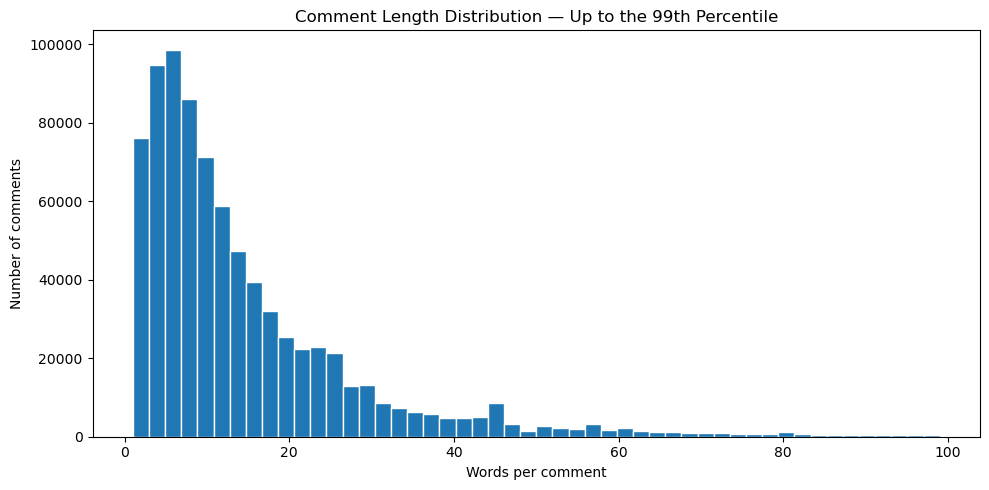

,body,word_count,sentiment
1001144,It went from 90 degrees and Sunny yesterday to 60 degrees and Rainy today here in Denver. Kinda resembles my portfolio this week,23,0.3612
40438,Oof,1,NaN
508300,Nobody gives af Take that shit to r/politics,8,-0.5574
431125,"I have purchased dips (Brexit, elections where the winner wasn't favored by the market, etc.), **but I don't trust China.**",20,-0.4251
219568,Smells like 🦍s in here,5,0.3612


In [4]:
import matplotlib.pyplot as plt

comments_clean["char_count"] = comments_clean["body"].str.len()
comments_clean["word_count"] = (
    comments_clean["body"].str.split().str.len()
)

# Summary includes the full range of comment lengths
display(
    comments_clean[["char_count", "word_count"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99])
    .round(2)
)

# Limit the chart to the 99th percentile for readability
upper_limit = comments_clean["word_count"].quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(
    comments_clean.loc[
        comments_clean["word_count"] <= upper_limit,
        "word_count"
    ],
    bins=50,
    edgecolor="white"
)
plt.title("Comment Length Distribution — Up to the 99th Percentile")
plt.xlabel("Words per comment")
plt.ylabel("Number of comments")
plt.tight_layout()
plt.show()

# Display complete sample comments without changing global settings
with pd.option_context("display.max_colwidth", None):
    display(
        comments_clean[["body", "word_count", "sentiment"]]
        .sample(5, random_state=42)
    )

### Interpretation of comment lengths

The median comment contains 10 words, while the mean is 15.80 words.
The higher mean reflects a small number of long comments. The 90th
percentile is 33 words, and the longest comment contains 1,648 words.
The histogram displays comments up to the 99th percentile of 99 words
for readability. Longer comments remain in the dataset.

The sample comments include brief reactions, informal language,
and discussions unrelated to specific stocks. This supports filtering
for ticker mentions before constructing stock-specific features.
Short comments may also require surrounding context to interpret
sentiment accurately.

One sample compares rainy weather with the author's portfolio and
receives a positive supplied sentiment score of 0.3612. This illustrates
why the supplied scores need review before being interpreted as
bullish or bearish trading sentiment.

### Ticker Extraction

In [5]:
# Keep the current list for exploration
tickers = [
    "GME", "AMC", "TSLA", "SPY", "QQQ", "AAPL", "AMD",
    "NVDA", "BABA", "CRWD", "PLTR", "BB", "NOK",
    "CLOV", "WISH", "SOFI", "SPCE", "HOOD"
]

ticker_options = "|".join(map(re.escape, tickers))

# Bare symbols must be uppercase: GME, WISH
# Dollar-prefixed symbols may use any case: $gme, $wish
ticker_pattern = re.compile(
    rf"(?<!\w)(?:"
    rf"\$(?P<cashtag>(?i:{ticker_options}))"
    rf"|(?P<uppercase>{ticker_options})"
    rf")(?!\w)"
)

def find_tickers(text):
    """Return unique recognized tickers mentioned in a comment."""
    found = {
        (match.group("cashtag") or match.group("uppercase")).upper()
        for match in ticker_pattern.finditer(str(text))
    }
    return sorted(found)

comments_clean["tickers"] = comments_clean["body"].apply(find_tickers)

ticker_comments = comments_clean.loc[
    comments_clean["tickers"].str.len() > 0
].copy()

ticker_counts = (
    ticker_comments["tickers"]
    .explode()
    .value_counts()
    .reindex(tickers, fill_value=0)
    .sort_values(ascending=False)
    .rename_axis("ticker")
    .reset_index(name="comment_count")
)

print(f"Comments mentioning a tracked ticker: {len(ticker_comments):,}")

display(ticker_counts)
display(ticker_comments[["body", "tickers"]].head(15))

Comments mentioning a tracked ticker: 64,905


,ticker,comment_count
0,SPY,17069
1,GME,8464
2,HOOD,6605
3,AMC,5515
4,CLOV,4951
5,WISH,3758
6,BABA,3624
7,PLTR,3608
8,AMD,3321
9,TSLA,3113


,body,tickers
4,Are you saying I should or shouldn’t yolo my life savings into BABA $200 call options expiring next week?,[BABA]
17,Buy more AMC or buy GME?,"[AMC, GME]"
65,If BB can get to 400 I will finally have recovered,[BB]
85,AMC,[AMC]
119,I’ve held GME before and sold,[GME]
125,"That's what I was thinking too, going to open a few spreads capping out in that range. GME has made me tens of thousands of dollars already this year, no sense getting greedy",[GME]
196,Too late to FOMO into GME? (Again),[GME]
211,"WISH, ASTR, PTON Calls",[WISH]
260,Who exactly is dumb enough to be caught with a short position large enough to get squeezed in this day and age. GME squeezed because nobody could get their heads around it going higher. But now e...,[GME]
266,"I pledge allegiance to the bags of the United States of America, and for which stands, one market, under all, invincible, with prosperity and otm call options for all. SPY to 500 eom.",[SPY]


### Ticker extraction findings

Our extraction rules identified 64,905 comments containing at least
one of the 18 tracked symbols. SPY had the most matching comments
(17,069), followed by GME (8,464) and HOOD (6,605). These counts
describe attention within our selected list, not all tickers on WSB.

Each ticker is counted once per comment. Comments mentioning multiple
tracked tickers contribute to each ticker's count, so the counts can
sum to more than the number of unique matching comments.

Requiring uppercase symbols or dollar-prefixed mentions reduces
false matches from ordinary lowercase words. However, it misses
lowercase symbols without a dollar sign, company names, and nicknames.
Uppercase ordinary words can still produce false matches.

SPY and QQQ are ETFs. We will distinguish these from individual stocks
and align the final symbol list with the trading-volume dataset.

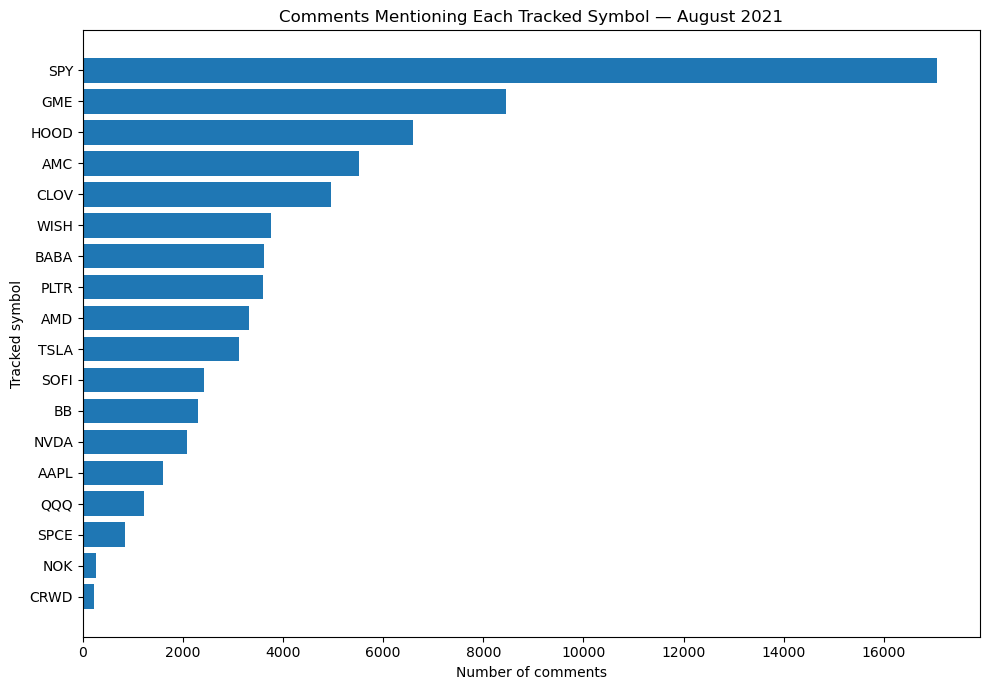

In [6]:
plot_counts = ticker_counts.sort_values("comment_count")

plt.figure(figsize=(10, 7))
plt.barh(plot_counts["ticker"], plot_counts["comment_count"])
plt.title("Comments Mentioning Each Tracked Symbol — August 2021")
plt.xlabel("Number of comments")
plt.ylabel("Tracked symbol")
plt.tight_layout()
plt.show()

### Before keyword analysis: need to review some tickers to check if ordinary words are getting through.

In [7]:
for ticker in ["WISH", "HOOD"]:
    matches = ticker_comments[
        ticker_comments["tickers"].apply(lambda values: ticker in values)
    ]

    print(f"\nSample matches for {ticker}:")
    with pd.option_context("display.max_colwidth", None):
        display(matches[["body", "tickers"]].sample(10, random_state=42))


Sample matches for WISH:


,body,tickers
508326,Things are not lookin too good for WISH bagholders....,[WISH]
601581,WISH's shareholder letter is probably the worst I've ever read. They may honestly go bankrupt within 2 years.,[WISH]
127290,WISH is loading. May be the next moon shot!!!,[WISH]
601313,"Wish is a scam pushed by this sub. I bought in and regret it. Every time I say that I do, get downvoted into oblivion. Someone made a thread how bad their earnings report from today was and it got deleted. WISH IS GARBAGE",[WISH]
571121,Nothing less than $9 for WISH.,[WISH]
812991,"Similar thing happened to my brother. Someone in Florida stole his identity and bought a house in his name. He called the sheriff in the area said they wouldn't have any part of it and advised him to talk to a lawyer instead. He went down to the property to confront the guy but he wasn't there and instead talked to his wife. He claimed to be a bounty hunter on the trail of himself, ""the stolen identity,"" due to skipped bail. The lady offered sex in exchange for him to abandon the, ""search,"" and he took her offer. He made sure to get the hell out of there before the identity thief came back and if you believed any of this, I got WISH calls to sell you.",[WISH]
570215,"The irony is the stock is called WISH, if anything anyone should always think twice before buying stock just based off that name alone.",[WISH]
168564,Fuck WISH man wtf,[WISH]
661584,I got a cheap ass hoodie off WISH,[WISH]
582882,what do you think about discount on WISH?,[WISH]



Sample matches for HOOD:


,body,tickers
783655,Bought 30c of HOOD expiring in 2023..😀.,[HOOD]
897542,HOOD wrong way,[HOOD]
192775,Literally no one expected anything of HOOD.,[HOOD]
910990,"Imagine buying HOOD at $48 today and then dropping at $45 cause u fear it tanking. Imagine, just imagine. Couldn't be me",[HOOD]
865931,"With the way this market moves, I wouldn’t be surprised by a massive pump in HOOD before an epic crash in the coming days",[HOOD]
622037,My short $70c HOOD lookin' GOOD this friday! Also GO 🍀! Crossing fingers for big green day.,[HOOD]
884715,"Damn I missed HOOD and MRNA runups this morning, sleeping in has its perks but that ain't one of em.",[HOOD]
898984,Way more profitable than HOOD. At least they rob ppl of money the proper way!,[HOOD]
910533,WSB finna get robbed in the $HOOD,[HOOD]
899136,HOOD,[HOOD]


### Manual review of ticker matches

We reviewed 10 randomly selected matches each for WISH and HOOD.
Most examples appeared relevant to the named company or stock.
However, the WISH sample included an unrelated story using
“WISH calls” as a joke and a comment about buying clothing from
the shopping platform.

Ticker matching therefore identifies candidate mentions rather
than verified stock discussions. Uppercase matching reduces
ordinary-word errors but does not resolve context. These small
samples do not establish accuracy across the full dataset.

For Phase III, we will review a larger sample and test whether
Claude can distinguish relevant stock discussion from unrelated
or ambiguous mentions before assigning trading sentiment.

### Daily comment activity and data coverage

We examine daily comment counts to check date coverage and variation
in discussion activity. We compare the original records with usable
comments to see how deleted, removed, and missing text affect coverage.

Dates are grouped in UTC for this descriptive check. Trading-day
features will require a separate market-time cutoff.

,original_comments,usable_comments,excluded_comments,excluded_percent
date_utc,,,,
2021-08-01 00:00:00+00:00,21563,18246,3317,15.38
2021-08-02 00:00:00+00:00,33357,27658,5699,17.08
2021-08-03 00:00:00+00:00,38443,31580,6863,17.85
2021-08-04 00:00:00+00:00,44860,36244,8616,19.21
2021-08-05 00:00:00+00:00,43376,33949,9427,21.73
2021-08-06 00:00:00+00:00,37271,29759,7512,20.16
2021-08-07 00:00:00+00:00,17691,14293,3398,19.21
2021-08-08 00:00:00+00:00,19049,15390,3659,19.21
2021-08-09 00:00:00+00:00,33312,25882,7430,22.30


Dates with no original records: 0


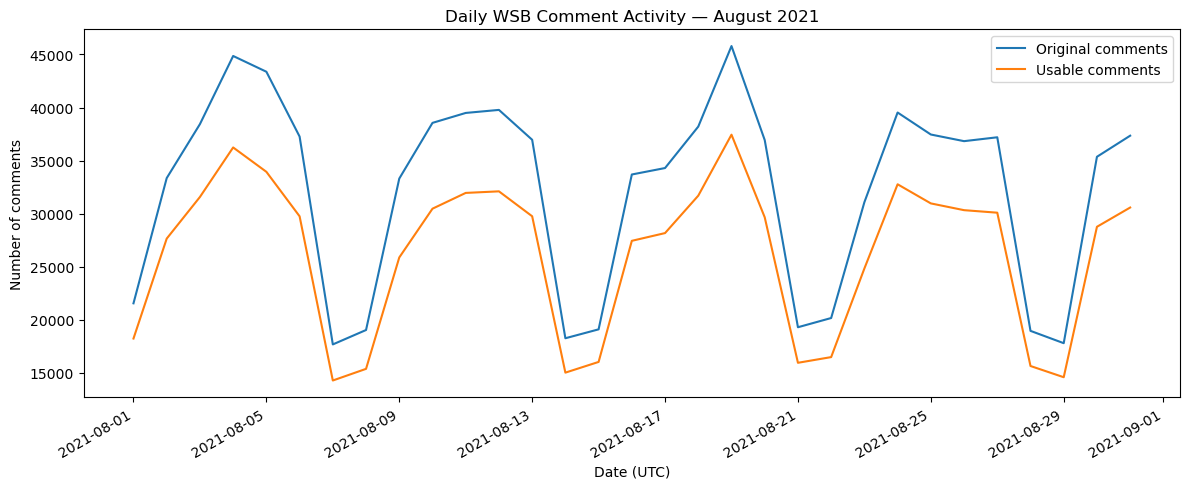

In [8]:
# Count original and usable comments by UTC calendar date
august_dates = pd.date_range(
    "2021-08-01", "2021-08-31", freq="D", tz="UTC"
)

daily_counts = pd.DataFrame({
    "original_comments": comments.groupby(
        comments["created_datetime"].dt.floor("D")
    ).size(),
    "usable_comments": comments_clean.groupby(
        comments_clean["created_datetime"].dt.floor("D")
    ).size()
}).reindex(august_dates, fill_value=0)

daily_counts.index.name = "date_utc"

daily_counts["excluded_comments"] = (
    daily_counts["original_comments"]
    - daily_counts["usable_comments"]
)

daily_counts["excluded_percent"] = (
    daily_counts["excluded_comments"]
    .div(daily_counts["original_comments"].replace(0, float("nan")))
    .mul(100)
    .round(2)
)

display(daily_counts)

print(
    "Dates with no original records:",
    (daily_counts["original_comments"] == 0).sum()
)

# Plot daily activity
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_counts.index,
    daily_counts["original_comments"],
    label="Original comments"
)
ax.plot(
    daily_counts.index,
    daily_counts["usable_comments"],
    label="Usable comments"
)

ax.set_title("Daily WSB Comment Activity — August 2021")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Number of comments")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Daily activity findings

All 31 UTC dates in August contain comments. Daily activity shows
a recurring weekly pattern, with lower counts on weekends.
August 19 had the highest activity, with 45,795 original comments
and 37,447 usable comments.

The original and cleaned series follow similar patterns, suggesting
that excluding unavailable text preserves the broad activity trend.
However, the percentage excluded varies from 15.38% to 22.30%
across dates. This variation could affect comparisons of mention
counts and sentiment between days.

No dates are entirely missing, but this does not establish that
every comment was collected. Weekend activity also shows why we
need explicit rules for assigning comments to trading-day windows.
These UTC daily totals are descriptive and are not yet the
features used to predict next-day volume.

### Which types of threads these comments come from

In [9]:
# Extract parent thread IDs and URL title slugs
thread_parts = comments_clean["permalink"].str.extract(
    r"/comments/(?P<thread_id>[^/]+)/(?P<thread_slug>[^/]+)"
)

comments_clean["thread_id"] = thread_parts["thread_id"]
comments_clean["thread_slug"] = thread_parts["thread_slug"]

# Classify threads using their URL title slugs
def classify_thread(slug):
    if pd.isna(slug):
        return "Unknown"
    if "daily_discussion" in slug:
        return "Daily discussion"
    if "what_are_your_moves" in slug:
        return "What are your moves"
    if "weekend_discussion" in slug:
        return "Weekend discussion"
    return "Other threads"

comments_clean["thread_type"] = (
    comments_clean["thread_slug"].apply(classify_thread)
)

thread_summary = (
    comments_clean["thread_type"]
    .value_counts()
    .rename_axis("thread_type")
    .reset_index(name="comment_count")
)

thread_summary["percent"] = (
    thread_summary["comment_count"]
    .div(len(comments_clean))
    .mul(100)
    .round(2)
)

display(thread_summary)

print(
    "Unique identified threads:",
    comments_clean["thread_id"].nunique()
)

,thread_type,comment_count,percent
0,Other threads,305679,37.56
1,Daily discussion,229312,28.17
2,What are your moves,198844,24.43
3,Weekend discussion,80100,9.84


Unique identified threads: 24467


### Thread coverage findings

The usable comments span 24,467 identified threads. Daily Discussion
threads account for 28.17% of comments, “What are your moves” threads
account for 24.43%, and Weekend Discussion threads account for 9.84%.
The remaining 37.56% appear in other threads.

This dataset has a broader scope than our original Daily Discussion
collection plan. For exploration, we retain all thread types and
identify candidate ticker mentions within them. Before modeling,
we will decide whether to retain this broader scope or restrict
the analysis to recurring discussion threads.

These categories are inferred from URL title slugs and may not
classify every thread correctly. Different thread types may also
contain different kinds of discussion, which could affect ticker
counts and sentiment.

## Daily Ticker Coverage

In [10]:
# One row per comment–ticker pair
ticker_daily_rows = (
    ticker_comments[["id", "created_datetime", "tickers"]]
    .explode("tickers")
    .rename(columns={"tickers": "ticker"})
)

ticker_daily_rows["date_utc"] = (
    ticker_daily_rows["created_datetime"].dt.floor("D")
)

# Include every tracked ticker and all 31 UTC dates
daily_ticker_counts = (
    ticker_daily_rows
    .groupby(["date_utc", "ticker"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=august_dates, columns=tickers, fill_value=0)
)

coverage_summary = pd.DataFrame({
    "total_candidate_comments": daily_ticker_counts.sum(),
    "days_with_mentions": daily_ticker_counts.gt(0).sum(),
    "zero_mention_days": daily_ticker_counts.eq(0).sum(),
    "median_daily_comments": daily_ticker_counts.median(),
    "max_daily_comments": daily_ticker_counts.max()
}).sort_values("total_candidate_comments", ascending=False)

display(coverage_summary)

,total_candidate_comments,days_with_mentions,zero_mention_days,median_daily_comments,max_daily_comments
ticker,,,,,
SPY,17069,31,0,593.0,1217
GME,8464,31,0,150.0,1877
HOOD,6605,31,0,65.0,2300
AMC,5515,31,0,154.0,608
CLOV,4951,31,0,86.0,860
WISH,3758,31,0,64.0,884
BABA,3624,31,0,90.0,504
PLTR,3608,31,0,80.0,542
AMD,3321,31,0,76.0,562


### Daily ticker coverage findings

Seventeen of the 18 tracked symbols have candidate mentions on every
UTC date in August. CRWD has mentions on 26 dates and no matches
on five dates.

Discussion volume differs substantially across symbols. SPY has a
median of 593 matching comments per day, compared with five for
NOK and three for CRWD. Sentiment averages based on only a few
comments may be less stable and should be accompanied by comment
counts.

Some symbols also show concentrated bursts of attention. HOOD
has a median of 65 matching comments per day but a maximum of
2,300. This supports examining changes in attention rather than
relying only on monthly totals. It does not establish that Reddit
activity predicts trading volume.

Zero-mention dates are retained. These represent no matches under
our extraction rules, rather than proof that no discussion occurred.
The counts use UTC calendar dates and will need to be reconstructed
using the agreed trading-day cutoff before modeling.

# 2.	Text Mining Basics (about 50% of the notebook)
- Keyword/frequency analysis: top keywords, word clouds, or bar charts
- Sentiment analysis: baseline sentiment scores (lexicon-based or a simple model) across your text
- Topic modeling or NER, only if relevant to your problem
- Use visuals (bar charts, word clouds, tables) and briefly interpret what you see. Make sure this ties back to your problem or informs your next-stage model building, rather than just checking off a list.


# 3.	Plan for Phase 3 (about 25% of the notebook)
- Which analysis path, A or B, are you pursuing, and why does the data or the business problem support it?
- If you plan to use Claude (or any other LLM of your choice: note the class only provides Claude API keys), what specifically will it do, and have you tried a few sample prompts?
- If you’re not using an LLM at all, explain why. That’s completely fine, and sometimes the better choice.
- Are there any concerns with your approach (privacy, scale, token usage, validity of LLM results, etc.)?
